# 01 · Which model should describe figures for a blind listener?

**Question.** hearxiv must turn each figure into a description that a blind researcher can *hear*.
Which vision model does this best, and what does it cost? We compare cloud APIs (OpenAI, Gemini free
tier) with open models that run **locally on a laptop CPU** (zero cost, fully private).

**Setup.**
* **18 standard seaborn / matplotlib figures** that look like ML papers: loss curves, model-comparison
  bars, confusion and attention heatmaps, violins, KDEs, regression, log-scale lines with CIs,
  multi-panel, facet grids, pair plots, clustermaps, ECDFs. Each is drawn from **seeded synthetic data**,
  so the answer key (title, axes, series, key numbers, trends) is known exactly from the plotting code
  (`benchmarks/figure_ocr/make_figures.py`).
* **One prompt for every model** (`hearxiv.vision.prompts`). It asks for the structure blind readers
  prefer (Lundgard & Satyanarayan 2021): overview, then axes, series, key numbers, pattern.
* **Two layers of scoring** (`benchmarks/figure_ocr/scoring.py`):
  1. *Automatic, no model bias:* chart type named, recall of title/axes/series (fuzzy match),
     and fact accuracy (numbers within tolerance, key phrases).
  2. *LLM judge* (`gpt-6.2-sol`, sees the image **and** the answer key): accuracy, completeness and
     listenability (0–5), plus a list of hallucinated claims.

**Hardware for local models:** AMD Ryzen 5 3500U (4 cores, 2019 laptop), 14 GB RAM, **no GPU**, float32.

In [1]:
import json, re, textwrap
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, HTML, Markdown
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BENCH = ROOT / "benchmarks" / "figure_ocr"
sys.path.insert(0, str(BENCH))
from scoring import auto_score

GT = {g["id"]: g for g in json.loads((BENCH / "ground_truth.json").read_text(encoding="utf-8"))}
CLOUD, LOCAL = "#2a78d6", "#eb6834"  # categorical slots 1-2 (validated palette)
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "font.size": 10})
pd.set_option("display.max_colwidth", 200)
print(len(GT), "figures")

18 figures


## The figure suite

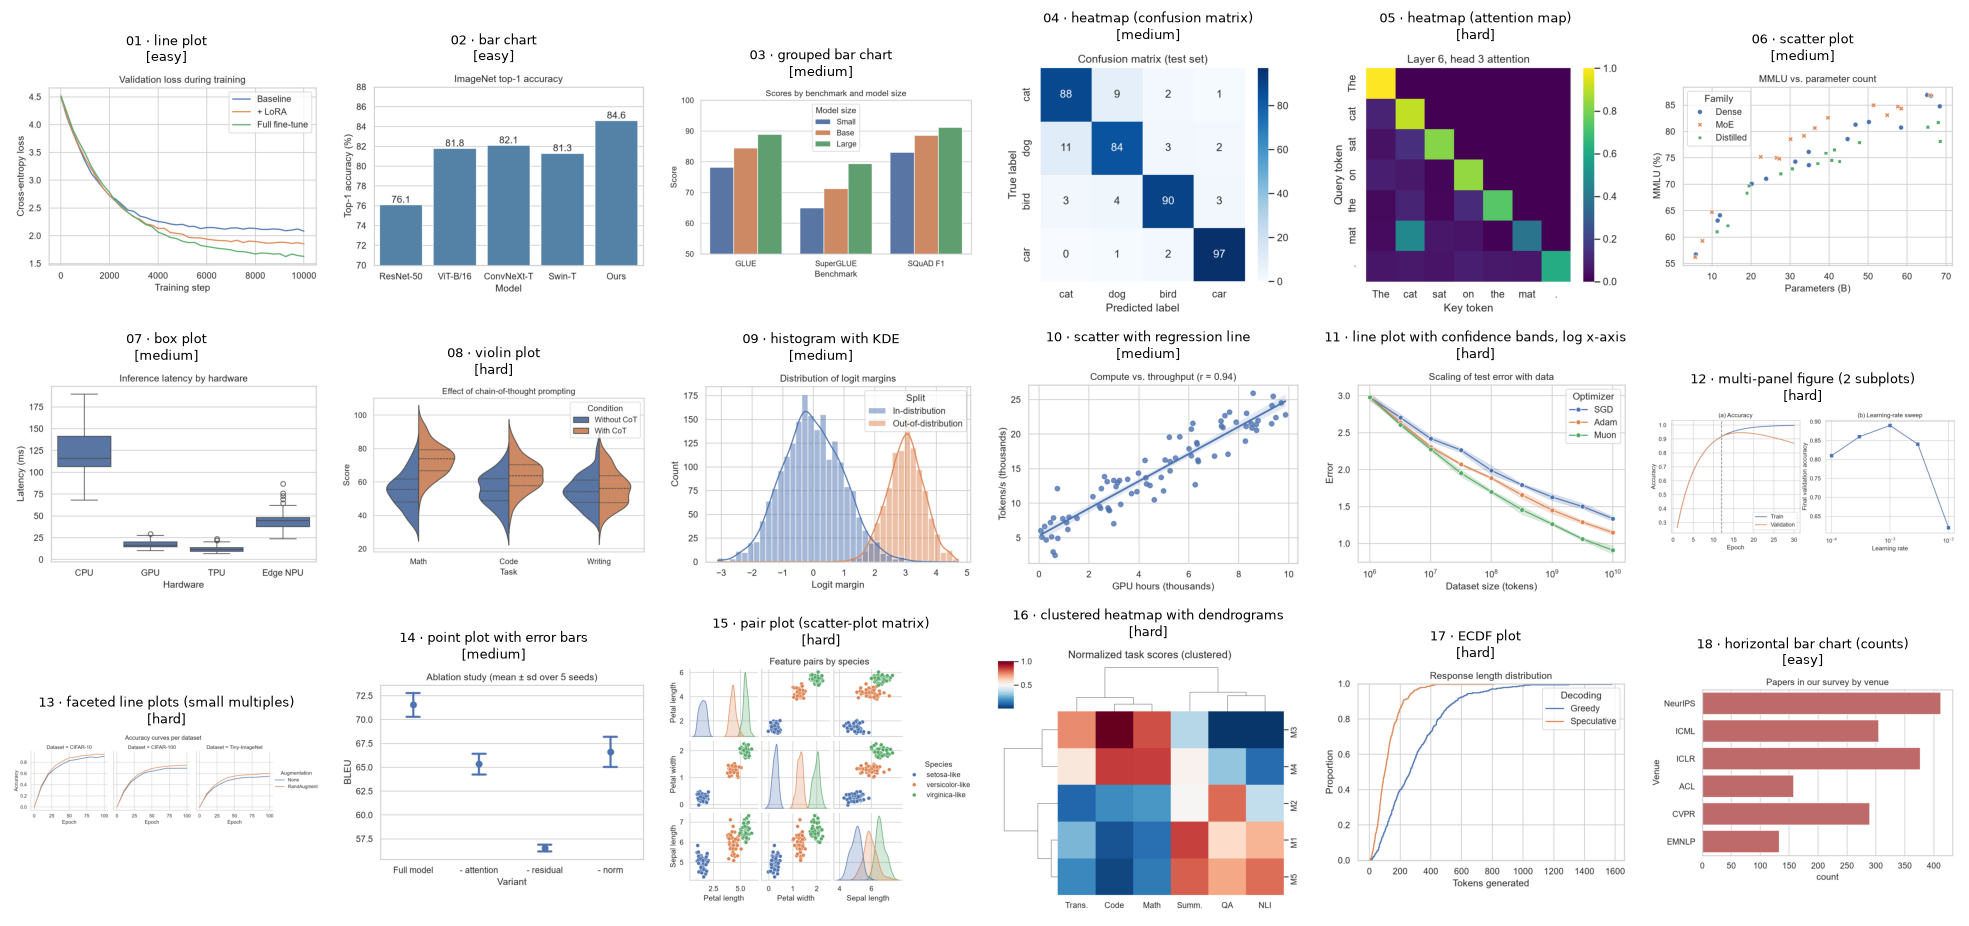

In [2]:
fig, axes = plt.subplots(3, 6, figsize=(18, 8.5))
for ax, (fid, g) in zip(axes.flat, GT.items()):
    ax.imshow(plt.imread(BENCH / g["file"])); ax.set_axis_off()
    ax.set_title(f"{fid[:2]} · {g['chart_type']}\n[{g['difficulty']}]", fontsize=8.5)
plt.tight_layout(); plt.show()

## Models tested

| Model | Where it runs | Size | Licence | Cost |
|---|---|---|---|---|
| `openai:gpt-6.2-astra` | OpenAI API | flagship | proprietary | $8 / $40 per 1M tokens (in / out) |
| `openai:gpt-6.1-terra` | OpenAI API | mid ("visual reasoning") | proprietary | $1 / $5 |
| `openai:gpt-6-luna` | OpenAI API | small | proprietary | $0.10 / $0.50 |
| `openai:gpt-5.4-mini` | OpenAI API | small, previous gen | proprietary | $0.75 / $4.50 |
| `gemini:gemini-3.8-flash` | Google API, **free tier** (≈20 req/day) — *only 5/18 done: repeated 503 "high demand"* | — | proprietary | $0 |
| `gemini:gemini-3.5-flash-lite` | Google API, **free tier** (≈500 req/day) | — | proprietary | $0 |
| `gemini:gemma-4-31b-it` | Google API (open-weights model) | 31B | Gemma (open) | $0 |
| `hf:Qwen/Qwen3.5-2B` | **local CPU** — *queued, not reached (run stopped: low memory)* | 2B | Apache-2.0 | $0 |
| `hf:Qwen/Qwen3.5-0.8B` | **local CPU** | 0.8B | Apache-2.0 | $0 |
| `hf:HuggingFaceTB/SmolVLM-256M-Instruct` | **local CPU** (Docling's default describer) | 256M | Apache-2.0 | $0 |
| `hf:ibm-granite/granite-docling-258M` | **local CPU**, chart-to-table mode — *only 3/18 done (≈1 h/figure under memory pressure)* | 258M | Apache-2.0 | $0 |

*Not run here:* **IBM Granite Vision 4.1 (4B)** and **Gemma 4 E2B/E4B**. In float32 they need more than
14 GB RAM, and bfloat16 is emulated (very slow) on this CPU. Quantised GGUF via llama.cpp is the way to run
them on a laptop, but unsigned `llama.cpp` binaries are blocked by Windows Smart App Control on this machine.
They are the first thing to add on a machine with a GPU or with llama.cpp available (`local:` provider).

**Reproduce:**
```bash
uv run python benchmarks/figure_ocr/make_figures.py
uv run python benchmarks/figure_ocr/run_benchmark.py openai:gpt-6.1-terra gemini:gemini-3.5-flash-lite
uv run python benchmarks/figure_ocr/run_benchmark.py hf:Qwen/Qwen3.5-2B --max-side 768 --max-new-tokens 400
uv run python benchmarks/figure_ocr/judge_results.py
```

## Load results and score

In [3]:
rows = {}
for f in sorted((BENCH / "results").glob("*.jsonl")):
    if f.name == "judgments.jsonl":
        continue
    for line in f.read_text(encoding="utf-8").splitlines():
        r = json.loads(line)
        if r.get("text") is not None and not r.get("error"):
            rows[(r["model"], r["figure_id"])] = r
res = pd.DataFrame(rows.values())
auto = pd.DataFrame([auto_score(GT[r.figure_id], r.text) for r in res.itertuples()])
res = pd.concat([res.reset_index(drop=True), auto], axis=1)

judg = pd.DataFrame([json.loads(l) for l in (BENCH / "results" / "judgments.jsonl").read_text(encoding="utf-8").splitlines()])
judg = judg.drop_duplicates(["model", "figure_id"], keep="last")
res = res.merge(judg[["model", "figure_id", "accuracy", "completeness", "listenability", "n_hallucinations",
                      "hallucinations", "rationale"]], on=["model", "figure_id"], how="left")

res["local"] = res.model.str.startswith("hf:")
res["short"] = res.model.str.replace(r"^(openai|gemini|hf):", "", regex=True).str.replace(r"^.*/", "", regex=True)
# models that did not finish all 18 figures are labelled with their coverage: their averages are over
# a subset and are not directly comparable
n_done = res.groupby("model").figure_id.transform("count")
res.loc[n_done < len(GT), "short"] = res.short + " (" + n_done.astype(str) + f"/{len(GT)}, partial)"
# composite quality in [0, 1]: equal weight on automatic facts/labels and judged accuracy/completeness
res["quality"] = (res.fact_acc + res.label_recall + res.accuracy / 5 + res.completeness / 5) / 4
print(res.groupby("model").size().to_string())

model
gemini:gemini-3.5-flash-lite                       18
gemini:gemini-3.8-flash                             5
gemini:gemma-4-31b-it                              17
hf:HuggingFaceTB/SmolVLM-256M-Instruct             18
hf:Qwen/Qwen3.5-0.8B                               18
hf:ibm-granite/granite-docling-258M@chart2table     3
openai:gpt-5.4-mini                                18
openai:gpt-6-luna                                  18
openai:gpt-6.1-terra                               18
openai:gpt-6.2-astra                               18


### Cost per figure
OpenAI list prices × measured tokens. Gemini free tier and local models cost $0 (local costs electricity
and time instead).

In [4]:
PRICE = {"gpt-6.2-astra": (8, 40), "gpt-6.1-terra": (1, 5), "gpt-6-luna": (0.10, 0.50), "gpt-5.4-mini": (0.75, 4.50)}
def cost(r):
    p = PRICE.get(r.short)
    if not p or pd.isna(r.input_tokens):
        return 0.0
    return (r.input_tokens * p[0] + r.output_tokens * p[1]) / 1e6
res["usd"] = res.apply(cost, axis=1)

## Leaderboard

In [5]:
lb = (res.groupby(["model", "short", "local"])
        .agg(figures=("figure_id", "count"), quality=("quality", "mean"), fact_acc=("fact_acc", "mean"),
             label_recall=("label_recall", "mean"), type_hit=("type_hit", "mean"),
             judge_accuracy=("accuracy", "mean"), judge_completeness=("completeness", "mean"),
             judge_listenability=("listenability", "mean"), hallucinations_per_fig=("n_hallucinations", "mean"),
             sec_per_fig=("seconds", "median"), words=("words", "median"), usd_per_fig=("usd", "mean"))
        .reset_index().sort_values("quality", ascending=False))
lb["usd_per_1000_figs"] = lb.usd_per_fig * 1000
show = lb.drop(columns=["model", "usd_per_fig"]).set_index("short")
display(show.style.format({c: "{:.2f}" for c in show.columns if c not in ("figures", "local", "words")} |
                          {"usd_per_1000_figs": "${:.2f}", "sec_per_fig": "{:.1f}s", "words": "{:.0f}"})
            .background_gradient(cmap=BLUES, subset=["quality", "fact_acc", "judge_accuracy", "judge_completeness"]))

,local,figures,quality,fact_acc,label_recall,type_hit,judge_accuracy,judge_completeness,judge_listenability,hallucinations_per_fig,sec_per_fig,words,usd_per_1000_figs
short,,,,,,,,,,,,,
gpt-6.1-terra,False,18,0.93,0.97,0.87,0.94,4.78,4.56,4.67,0.22,8.4s,162,$3.09
gpt-6.2-astra,False,18,0.91,0.93,0.78,1.00,4.89,4.72,4.72,0.11,6.9s,204,$18.09
"gemini-3.8-flash (5/18, partial)",False,5,0.89,0.90,0.85,1.00,4.40,4.60,4.60,1.40,163.2s,226,$0.00
gpt-6-luna,False,18,0.89,0.93,0.84,1.00,4.33,4.56,4.50,1.00,5.3s,178,$0.36
"gemma-4-31b-it (17/18, partial)",False,17,0.86,0.91,0.83,1.00,4.00,4.47,5.00,1.71,110.4s,156,$0.00
gpt-5.4-mini,False,18,0.86,0.90,0.86,1.00,4.06,4.28,4.06,1.78,3.4s,228,$2.22
gemini-3.5-flash-lite,False,18,0.85,0.86,0.89,1.00,3.67,4.67,4.56,2.17,2.0s,200,$0.00
Qwen3.5-0.8B,True,18,0.68,0.80,0.86,0.78,2.17,3.06,3.28,5.72,103.3s,179,$0.00
"granite-docling-258M@chart2table (3/18, partial)",True,3,0.33,0.33,0.61,0.00,1.00,1.00,0.00,4.67,3836.9s,8,$0.00


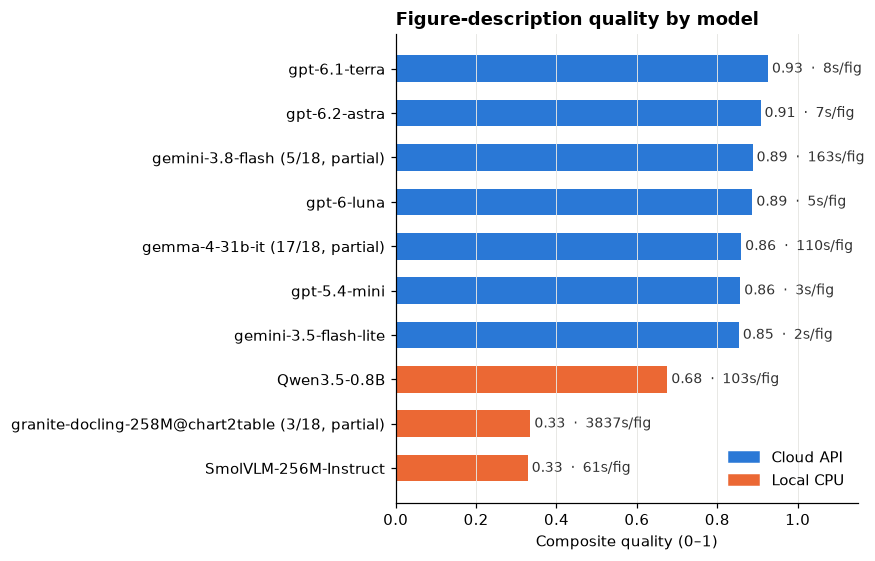

In [6]:
fig, ax = plt.subplots(figsize=(8, 0.42 * len(lb) + 1))
lbs = lb.sort_values("quality")
ax.barh(lbs.short, lbs.quality, color=[LOCAL if l else CLOUD for l in lbs.local], height=0.6)
for y, (q, s) in enumerate(zip(lbs.quality, lbs.sec_per_fig)):
    ax.text(q + 0.01, y, f"{q:.2f}  ·  {s:.0f}s/fig", va="center", fontsize=9, color="#333")
ax.set_xlim(0, 1.15); ax.set_xlabel("Composite quality (0–1)"); ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CLOUD), plt.Rectangle((0, 0), 1, 1, color=LOCAL)],
          labels=["Cloud API", "Local CPU"], loc="lower right", frameon=False)
ax.set_title("Figure-description quality by model", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## Quality vs. latency

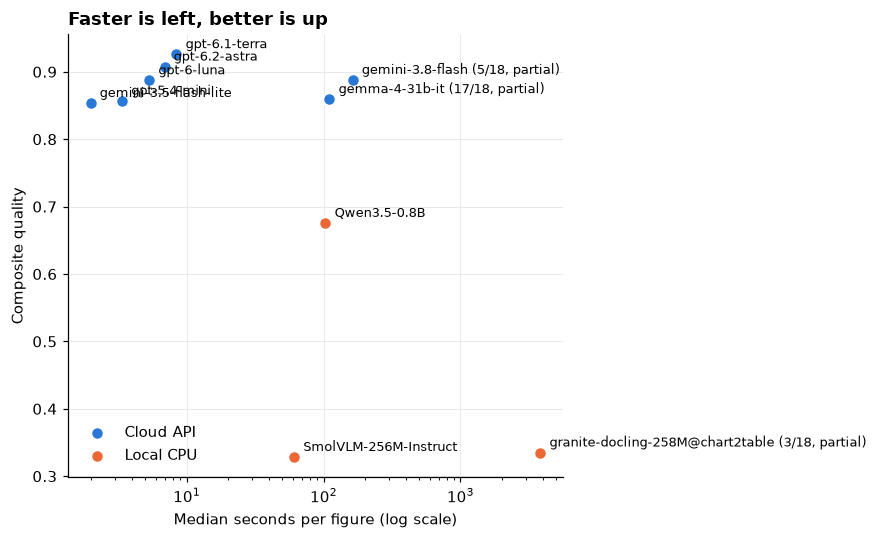

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
for loc, col, lab in [(False, CLOUD, "Cloud API"), (True, LOCAL, "Local CPU")]:
    d = lb[lb.local == loc]
    ax.scatter(d.sec_per_fig, d.quality, s=70, color=col, label=lab, edgecolor="white", linewidth=1.5, zorder=3)
    for r in d.itertuples():
        ax.annotate(r.short, (r.sec_per_fig, r.quality), xytext=(6, 4), textcoords="offset points", fontsize=8.5)
ax.set_xscale("log"); ax.set_xlabel("Median seconds per figure (log scale)"); ax.set_ylabel("Composite quality")
ax.legend(frameon=False, loc="lower left"); ax.set_title("Faster is left, better is up", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## Where models fail: quality per figure

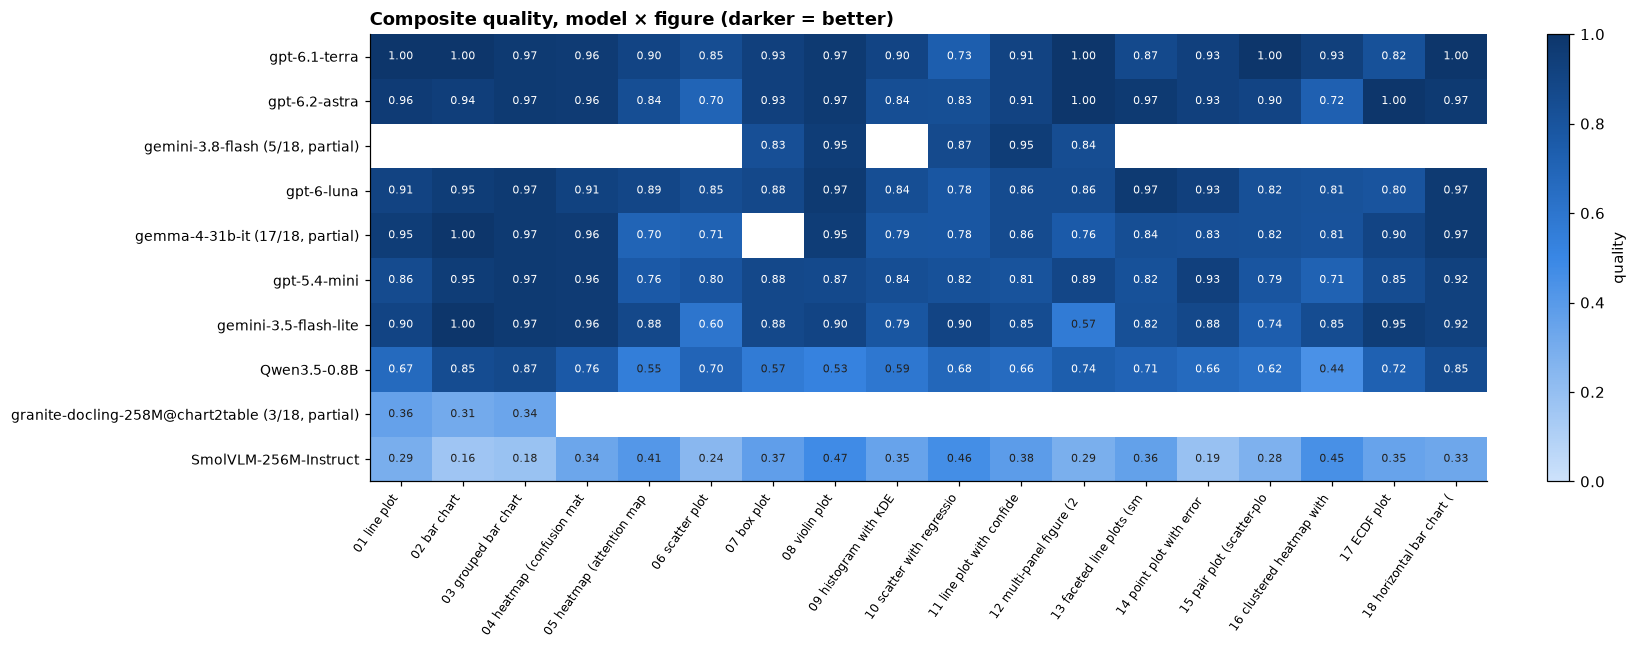

In [8]:
order_models = lb.short.tolist()
piv = res.pivot_table(index="short", columns="figure_id", values="quality").reindex(order_models)
fig, ax = plt.subplots(figsize=(15, 0.45 * len(piv) + 1.5))
im = ax.imshow(piv.values, cmap=BLUES, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(piv.shape[1]), [c[:2] + " " + GT[c]["chart_type"][:22] for c in piv.columns], rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(piv.shape[0]), piv.index, fontsize=9); ax.grid(False)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 else "#222")
fig.colorbar(im, ax=ax, fraction=0.02, label="quality")
ax.set_title("Composite quality, model × figure (darker = better)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

In [9]:
by_diff = res.pivot_table(index="short", columns=res.figure_id.map(lambda f: GT[f]["difficulty"]),
                          values="quality").reindex(order_models)[["easy", "medium", "hard"]]
display(by_diff.style.format("{:.2f}").background_gradient(cmap=BLUES, vmin=0, vmax=1))

figure_id,easy,medium,hard
short,,,
gpt-6.1-terra,1.00,0.90,0.92
gpt-6.2-astra,0.96,0.88,0.91
"gemini-3.8-flash (5/18, partial)",nan,0.85,0.91
gpt-6-luna,0.94,0.88,0.87
"gemma-4-31b-it (17/18, partial)",0.97,0.84,0.83
gpt-5.4-mini,0.91,0.88,0.81
gemini-3.5-flash-lite,0.94,0.85,0.82
Qwen3.5-0.8B,0.79,0.69,0.62
"granite-docling-258M@chart2table (3/18, partial)",0.33,0.34,nan


## The description table
For every figure, each model's description and its scores (A = judge accuracy, C = completeness,
facts = automatic fact accuracy). This is the qualitative heart of the benchmark: read a few rows.


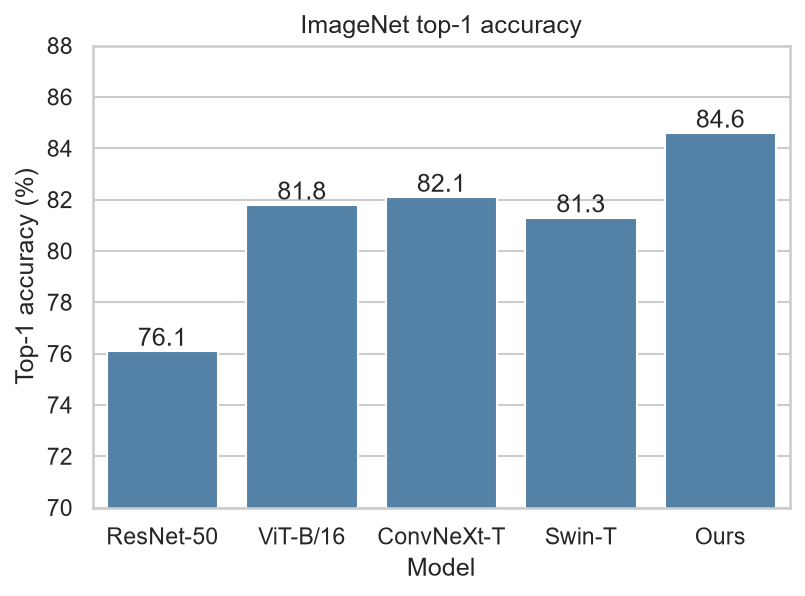


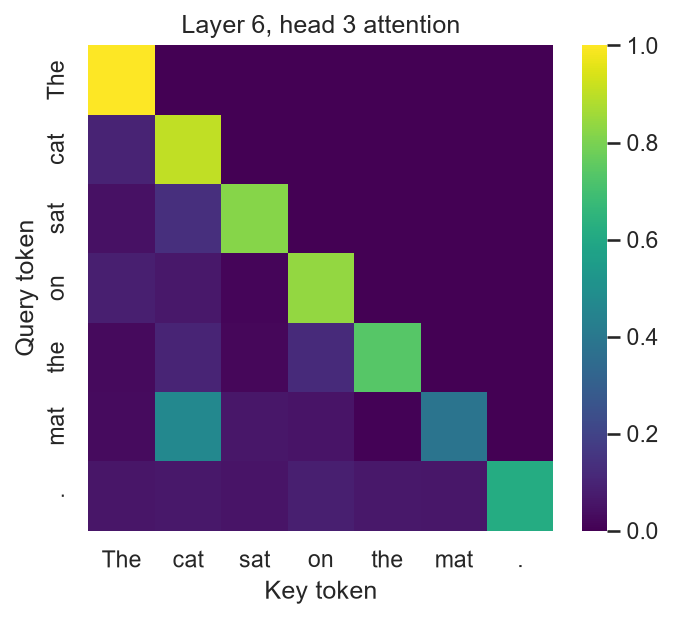


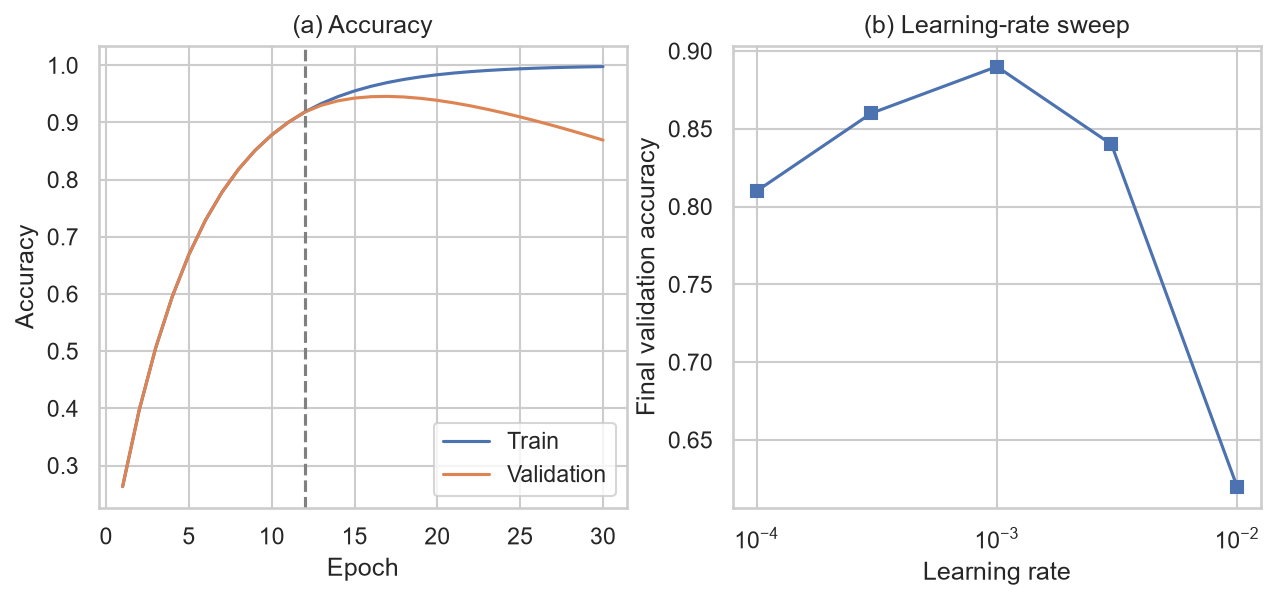


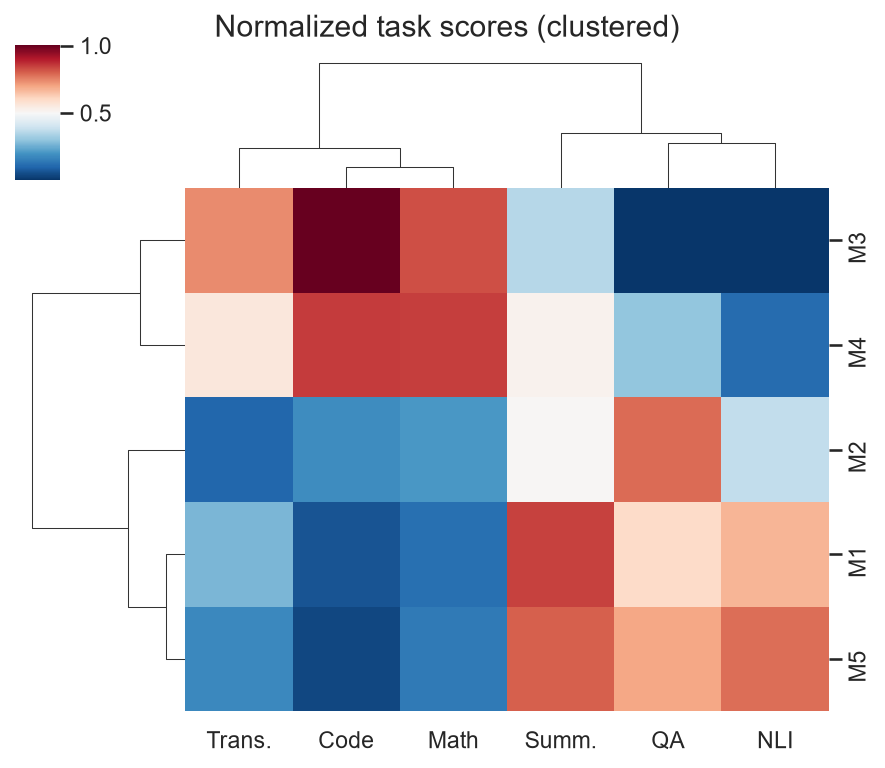

In [10]:
import base64, html
def thumb(path, w=260):
    return f'<img src="data:image/png;base64,{base64.b64encode(Path(path).read_bytes()).decode()}" width="{w}">'

def figure_table(fid):
    d = res[res.figure_id == fid].set_index("short").reindex([m for m in order_models if m in set(res[res.figure_id == fid].short)])
    cells = "".join(
        f"<tr><td style='vertical-align:top;white-space:nowrap'><b>{m}</b><br>A {r.accuracy:.0f} · C {r.completeness:.0f}"
        f"<br>facts {r.fact_acc:.2f}<br>{r.seconds:.0f}s</td>"
        f"<td style='vertical-align:top;text-align:left;font-size:12px'>{html.escape(r.text)}"
        + (f"<br><span style='color:#b3261e'>✗ {html.escape('; '.join(r.hallucinations))}</span>"
           if isinstance(r.hallucinations, list) and r.hallucinations else "")
        + "</td></tr>" for m, r in d.iterrows())
    g = GT[fid]
    return (f"<h4>{fid} · {g['chart_type']} [{g['difficulty']}]</h4><table><tr><td colspan=2>{thumb(BENCH / g['file'])}</td></tr>"
            f"{cells}</table>")

for fid in ["02_bar_benchmark_accuracy", "05_heatmap_attention_unannotated", "12_multi_panel_subplots", "16_clustermap"]:
    display(HTML(figure_table(fid)))

In [11]:
# Full side-by-side table (all figures x all models) exported for browsing on GitHub
lines = ["# Figure descriptions by model\n", "Generated by notebooks/01_figure_description_benchmark.ipynb.\n"]
for fid, g in GT.items():
    lines.append(f"\n## {fid} · {g['chart_type']} [{g['difficulty']}]\n\n![{fid}](figures/{fid}.png)\n")
    lines.append("| model | judge acc / compl | facts | description |\n|---|---|---|---|")
    for m in order_models:
        r = res[(res.figure_id == fid) & (res.short == m)]
        if r.empty:
            continue
        r = r.iloc[0]
        txt = r.text.replace("\n", " ").replace("|", "\\|")
        lines.append(f"| {m} | {r.accuracy:.0f} / {r.completeness:.0f} | {r.fact_acc:.2f} | {txt} |")
(BENCH / "DESCRIPTIONS.md").write_text("\n".join(lines), encoding="utf-8")
print("wrote", BENCH / "DESCRIPTIONS.md")

wrote D:\Root\Repositories\Personal\hearxiv\benchmarks\figure_ocr\DESCRIPTIONS.md


## Failure analysis: what goes wrong?

In [12]:
from collections import Counter
miss = Counter(f for fs in res.missed_facts for f in fs)
display(pd.DataFrame(miss.most_common(15), columns=["fact most often missed (all models)", "models missing it"]))
worst = res.sort_values("quality").head(8)[["short", "figure_id", "quality", "rationale"]]
display(worst)

,fact most often missed (all models),models missing it
0,diminishing returns / log-like curve,8
1,OOD narrower / fewer samples,6
2,panel (b) best learning rate 1e-3,6
3,shaded bands show variability across seeds,5
4,lower-triangular / causal mask (upper triangle empty),5
5,MoE tends highest,3
6,validation diverges from train after epoch 12 (overfitting),3
7,accuracy collapses to 0.62 at 1e-2,3
8,petal features strongly correlated,3
9,color scale from 0 to 1,3


,short,figure_id,quality,rationale
41,SmolVLM-256M-Instruct,02_bar_benchmark_accuracy,0.162500,"The sentence correctly identifies the metric, but 88% is the top y-axis tick, not a model's accuracy; Ours leads at 84.6%. It is easy to hear but too terse to convey the bar chart, its five models..."
42,SmolVLM-256M-Instruct,03_grouped_bar_hue,0.183333,"The description correctly names only SQuAD F1 and omits the grouped bar chart structure, axes, model sizes, key scores, and the main patterns: larger models score higher on every benchmark, and Su..."
53,SmolVLM-256M-Instruct,14_pointplot_ablation,0.185714,"The description repeats the title but replaces the figure’s findings with a generic, repetitive explanation. It omits the point plot, both axes, the four variants, the BLEU scores, the standard-de..."
45,SmolVLM-256M-Instruct,06_scatter_hue,0.241667,"The description correctly mentions parameter count, but it is too terse to orient a listener. It omits the scatter plot format, axis units, all three model families, the maximum of about 70 billio..."
54,SmolVLM-256M-Instruct,15_pairplot,0.275000,"The title is correct and easy to hear, but it is too terse to serve as a figure description. It omits the scatter-plot matrix, axis variables, species groups, diagonal distributions, and main patt..."
51,SmolVLM-256M-Instruct,12_multi_panel_subplots,0.287500,"The description is brief and easy to follow, but it conflates the two panels and gives incorrect axis ranges. It omits the training and validation curves' divergence after epoch 12 and fails to id..."
40,SmolVLM-256M-Instruct,01_line_loss_curves,0.291667,"The description states the title correctly but omits the plot type, axes, three series, key values, and the overall decline in loss. The title is clear when read aloud, but it is too terse to serv..."
59,"granite-docling-258M@chart2table (3/18, partial)",02_bar_benchmark_accuracy,0.310417,"The candidate names all five models and both axis labels, but only ResNet-50 is paired with its correct Top-1 value; the other four values are wrong, and three unsupported metrics are added. It om..."


## Conclusions
*(full table and caveats in [`benchmarks/figure_ocr/README.md`](../benchmarks/figure_ocr/README.md))*

**Recommendation: describe figures with `gpt-6.1-terra` at ingest, once per paper, and cache the result.**

1. **Best overall.** `gpt-6.1-terra` has quality 0.93 and the highest fact accuracy (0.97).
   - It averages only 0.22 hallucinated claims per figure.
   - It costs about $3 per 1,000 figures, which is 2–3 cents for a typical paper.
2. **`gpt-6.2-astra` is the most careful** (0.11 hallucinations per figure, judge accuracy 4.89), but it costs
   6× more for no gain in composite quality.
3. **`gpt-6-luna` is the value pick**: quality 0.89 at $0.36 per 1,000 figures.
4. **Zero-cost cloud.** `gemini-3.5-flash-lite` (free tier) is the fastest model here (2 s) and scores 0.85.
   - It invents about two claims per figure, usually wrong numbers.
   - For a blind listener, a confident wrong number is the worst failure, because they cannot check it.
     Use it only as a fallback.
   - Gemini 3.8 Flash looks better (0.89 on 5 figures), but the free tier kept returning 503 errors.
5. **Open weights.** `gemma-4-31b-it` (0.86) is the best open model tested, but it is not laptop-sized.
6. **Tiny local models are not usable yet** on this CPU.
   - Qwen3.5-0.8B scores 0.68, invents about 6 claims per figure and takes about 100 s per figure.
   - SmolVLM-256M and Granite-Docling's chart-to-table mode both score about 0.33.
   - The next experiment is quantised 2–4B models through llama.cpp: Qwen3.5-2B/4B, Granite Vision 4.1 and
     Gemma 4 E4B.
7. **What every model misses is patterns, not values.** Examples: diminishing returns, divergence after
   epoch 12, what the shaded bands mean, the causal mask, and facts inside one panel of a multi-panel figure.
   The prompt asks for "the pattern" explicitly. This is also why figures get a short form at first mention
   and a long form on request.

**What this means for zero cost.** Listening is already free: Phonon and Moonshine run locally. The one
paid step is figure description, and it happens once per paper. A shared ingest cache, computed with
terra, makes the result free for every later listener.

**Caveats:**
- The figures are synthetic; real paper figures are planned for notebook 06.
- The judge is an OpenAI model. The automatic checks, which do not use the judge, give a similar ranking.
- Gemini 3.8 Flash, Gemma and Granite-Docling are partial runs.
- Qwen3.5-2B was not reached: the run was stopped when the machine ran low on memory.
